<a href="https://colab.research.google.com/github/nourmo7amed2317-png/library/blob/main/Laptop_Price_Predictions_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#pta-001
#pta-111

## import libararies

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('ggplot')
pd.set_option('display.max_columns', None) #to explory data better
from sklearn.preprocessing import MinMaxScaler

## add the database

In [ ]:
df=pd.read_csv(r"/content/laptop_prices.csv")

## understanding data

In [ ]:
df.head()

,Company,Product,TypeName,Inches,Ram,OS,Weight,Price_euros,Screen,ScreenW,ScreenH,Touchscreen,IPSpanel,RetinaDisplay,CPU_company,CPU_freq,CPU_model,PrimaryStorage,SecondaryStorage,PrimaryStorageType,SecondaryStorageType,GPU_company,GPU_model
0,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1.37,1339.69,Standard,2560,1600,No,Yes,Yes,Intel,2.3,Core i5,128,0,SSD,No,Intel,Iris Plus Graphics 640
1,Apple,Macbook Air,Ultrabook,13.3,8,macOS,1.34,898.94,Standard,1440,900,No,No,No,Intel,1.8,Core i5,128,0,Flash Storage,No,Intel,HD Graphics 6000
2,HP,250 G6,Notebook,15.6,8,No OS,1.86,575.00,Full HD,1920,1080,No,No,No,Intel,2.5,Core i5 7200U,256,0,SSD,No,Intel,HD Graphics 620
3,Apple,MacBook Pro,Ultrabook,15.4,16,macOS,1.83,2537.45,Standard,2880,1800,No,Yes,Yes,Intel,2.7,Core i7,512,0,SSD,No,AMD,Radeon Pro 455
4,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1.37,1803.60,Standard,2560,1600,No,Yes,Yes,Intel,3.1,Core i5,256,0,SSD,No,Intel,Iris Plus Graphics 650


In [ ]:
df.info()
#found no null values to remove

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Company               1275 non-null   object 
 1   Product               1275 non-null   object 
 2   TypeName              1275 non-null   object 
 3   Inches                1275 non-null   float64
 4   Ram                   1275 non-null   int64  
 5   OS                    1275 non-null   object 
 6   Weight                1275 non-null   float64
 7   Price_euros           1275 non-null   float64
 8   Screen                1275 non-null   object 
 9   ScreenW               1275 non-null   int64  
 10  ScreenH               1275 non-null   int64  
 11  Touchscreen           1275 non-null   object 
 12  IPSpanel              1275 non-null   object 
 13  RetinaDisplay         1275 non-null   object 
 14  CPU_company           1275 non-null   object 
 15  CPU_freq             

In [ ]:
df.describe()
#statistical summary

,Inches,Ram,Weight,Price_euros,ScreenW,ScreenH,CPU_freq,PrimaryStorage,SecondaryStorage
count,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000
mean,15.022902,8.440784,2.040525,1134.969059,1900.043922,1073.904314,2.302980,444.517647,176.069020
std,1.429470,5.097809,0.669196,700.752504,493.346186,283.883940,0.503846,365.537726,415.960655
min,10.100000,2.000000,0.690000,174.000000,1366.000000,768.000000,0.900000,8.000000,0.000000
25%,14.000000,4.000000,1.500000,609.000000,1920.000000,1080.000000,2.000000,256.000000,0.000000
50%,15.600000,8.000000,2.040000,989.000000,1920.000000,1080.000000,2.500000,256.000000,0.000000
75%,15.600000,8.000000,2.310000,1496.500000,1920.000000,1080.000000,2.700000,512.000000,0.000000
max,18.400000,64.000000,4.700000,6099.000000,3840.000000,2160.000000,3.600000,2048.000000,2048.000000


In [ ]:
df.dtypes

,0
Company,object
Product,object
TypeName,object
Inches,float64
Ram,int64
OS,object
Weight,float64
Price_euros,float64
Screen,object
ScreenW,int64


## Data preperation/ cleaning

In [ ]:
df.isnull().sum()
#no null

,0
Company,0
Product,0
TypeName,0
Inches,0
Ram,0
OS,0
Weight,0
Price_euros,0
Screen,0
ScreenW,0


In [ ]:
df.duplicated().sum()
#no duplicates

np.int64(0)

In [ ]:
df.rename(columns={"ScreenW":"Screen_widht",
                   "ScreenH":"Screen_hight"}, inplace=True)
#more readable

In [ ]:
df['Touchscreen'].unique()
df['IPSpanel'].unique()
df['RetinaDisplay'].unique()

array(['Yes', 'No'], dtype=object)

In [ ]:
#encoding categorical variables
#but making sure they are all yes and no without extra spaces or anything
#all to avoid turning them into null when mapping
df['Touchscreen'] = (
    df['Touchscreen']
    #convert into strings
    .astype(str)
    #remove extra spaces
    .str.strip()
    #turn all into lower case
    .str.lower()
    #maping
    .map({'yes': 1, 'no': 0})
)
df['IPSpanel'] = (
    df['IPSpanel']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'yes': 1, 'no': 0})
)
df['RetinaDisplay'] = (
    df['RetinaDisplay']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'yes': 1, 'no': 0})
)

<Axes: xlabel='Price_euros'>

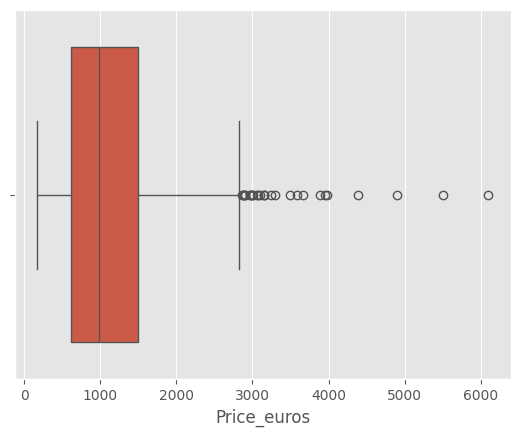

In [ ]:
#checking for outliers
sns.boxplot(x=df['Price_euros'])

In [ ]:
#couldnt remove them bec they are real prices not just error or unreal outliers
#log them bec they are just small amount
df['Price_euros_log'] = np.log(df['Price_euros'])

<Axes: xlabel='Inches'>

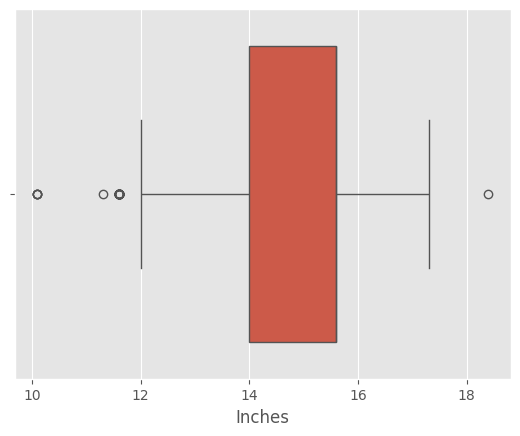

In [ ]:
#outliers for all numeric columns
sns.boxplot(x=df['Inches'])

In [ ]:
Q1 = df['Inches'].quantile(0.25)
Q3 = df['Inches'].quantile(0.75)
IQR = Q3 - Q1
# jhon turky rule
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
#remove inches higher than upper and smaller than lower
df = df[(df['Inches'] >= lower) & (df['Inches'] <= upper)]


<Axes: xlabel='Ram'>

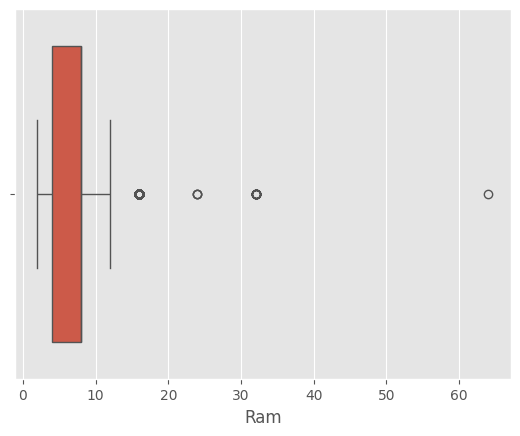

In [ ]:
sns.boxplot(x=df['Ram'])
#they are not outliers but real data

<Axes: xlabel='Weight'>

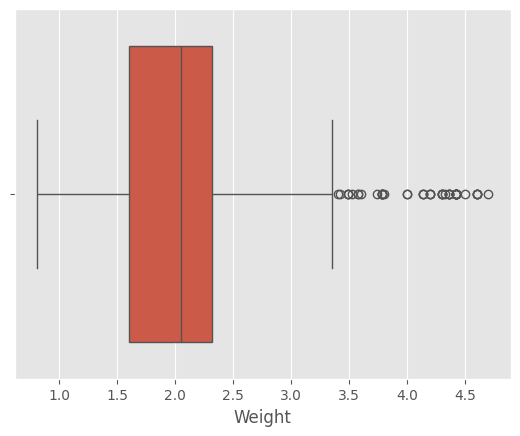

In [ ]:
sns.boxplot(x=df['Weight'])

<Axes: xlabel='Screen_widht'>

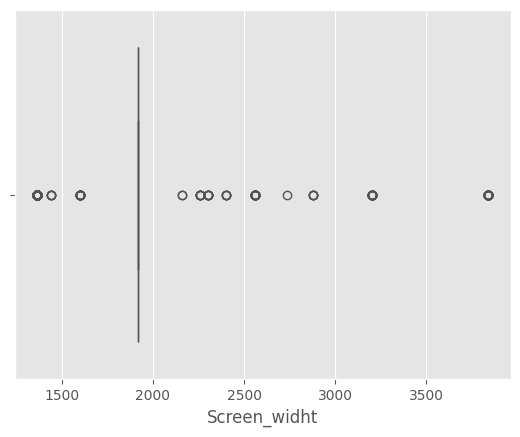

In [ ]:
sns.boxplot(x=df['Screen_widht'])
#not removing

<Axes: xlabel='Screen_hight'>

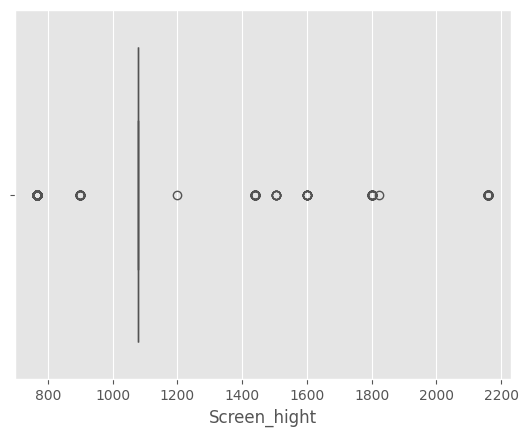

In [ ]:
sns.boxplot(x=df['Screen_hight'])

In [ ]:
Q1 = df['Screen_hight'].quantile(0.25)
Q3 = df['Screen_hight'].quantile(0.75)
IQR = Q3 - Q1
# jhon turky rule
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
#remove inches higher than upper and smaller than lower
df = df[(df['Screen_hight'] >= lower) & (df['Screen_hight'] <= upper)]

<Axes: xlabel='CPU_freq'>

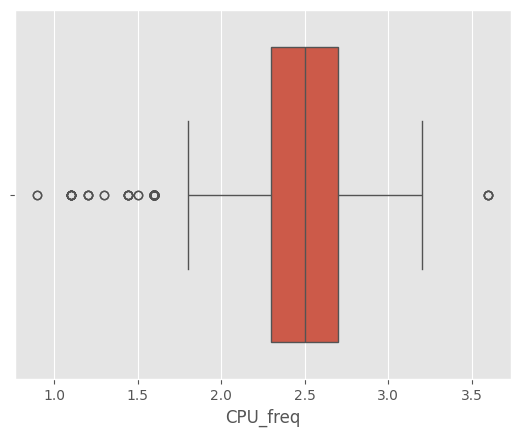

In [ ]:
sns.boxplot(x=df['CPU_freq'])

In [ ]:
Q1 = df['CPU_freq'].quantile(0.25)
Q3 = df['CPU_freq'].quantile(0.75)
IQR = Q3 - Q1
# jhon turky rule
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
#remove inches higher than upper and smaller than lower
df = df[(df['CPU_freq'] >= lower) & (df['CPU_freq'] <= upper)]

<Axes: xlabel='PrimaryStorage'>

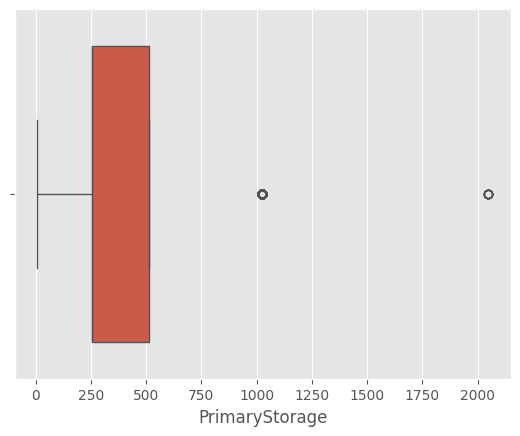

In [ ]:
sns.boxplot(x=df['PrimaryStorage'])

<Axes: xlabel='SecondaryStorage'>

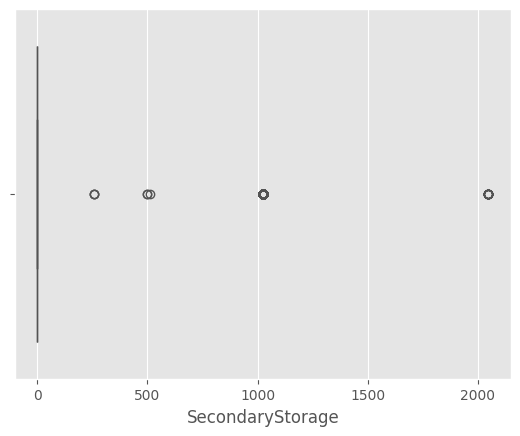

In [ ]:
sns.boxplot(x=df['SecondaryStorage'])
#this box blot looks weird because some devices had secondary storage
#and some didnt so they are real data not just an outliers

## adding new features
by asking questions about the data to identify what do you need to know /add

In [ ]:
#what is the total storage for every device?
df['Total_Storage_GB'] = df['PrimaryStorage'] + df['SecondaryStorage']
#prices depend on total storage not how many drives

In [ ]:
#which devices are considered to have a high ram value?
df['RAM_Category'] = pd.cut(
    df['Ram'],
    bins=[0,8,16,32,64],
    labels=['Low','Medium','High','Very High']
)
#grouping every ram value into a category

In [ ]:
#which devices screens are better?
df['Screen_Pixels'] = df['Screen_widht'] * df['Screen_hight']
#numeric so more obvious

In [ ]:
#is this device a value for money?
df['Price_per_GB_RAM'] = df['Price_euros'] / df['Ram']
df['Price_per_GB_Storage'] = df['Price_euros'] / df['Total_Storage_GB']

## preforming EDA
plotting relationships to understan them more

<Axes: xlabel='count', ylabel='Company'>

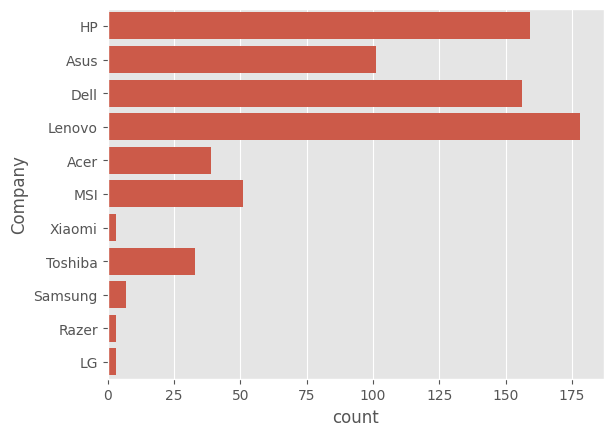

In [ ]:
#which brand appear more frequently?
sns.countplot(y='Company', data=df)


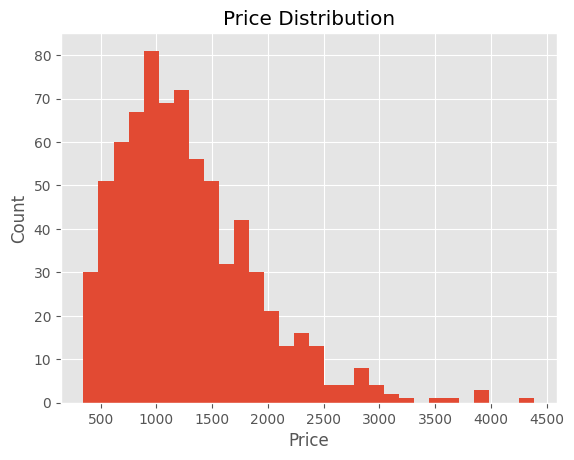

In [ ]:
#understanding the price distribution
plt.hist(df['Price_euros'], bins=30)
plt.xlabel('Price')
plt.ylabel('Count')
plt.title('Price Distribution')
plt.show()

<Axes: xlabel='Company', ylabel='Price_euros'>

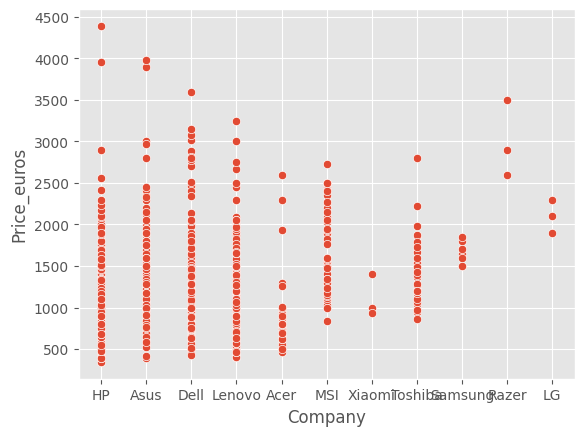

In [ ]:
#which brand have higher/ lower prices
sns.scatterplot(x='Company', y='Price_euros', data=df)
#some companies have a better variety in prices like HP ,Asus etc
#and its probably bec they appear more in this dataset
#while others dont like LG

Text(0.5, 1.0, 'Ram vs Price')

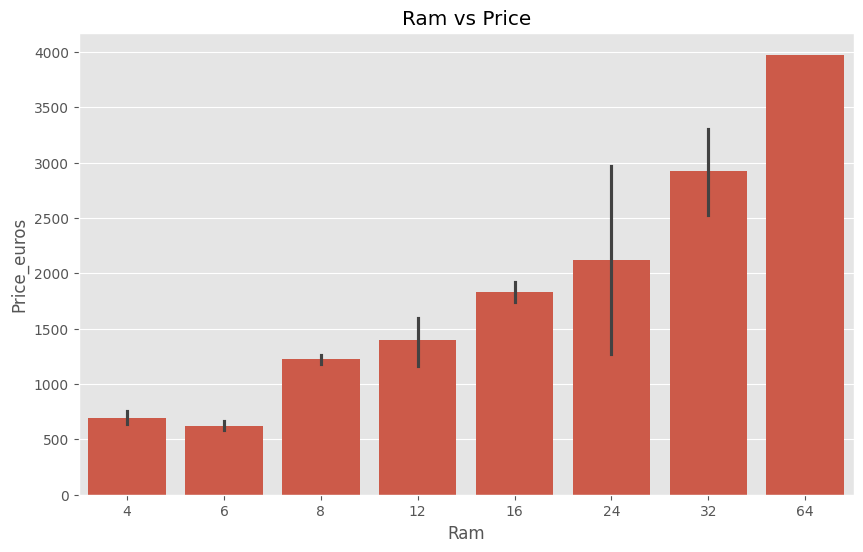

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Ram', y='Price_euros', data=df)
plt.title('Ram vs Price')

Text(0.5, 1.0, 'TypeName vs Price')

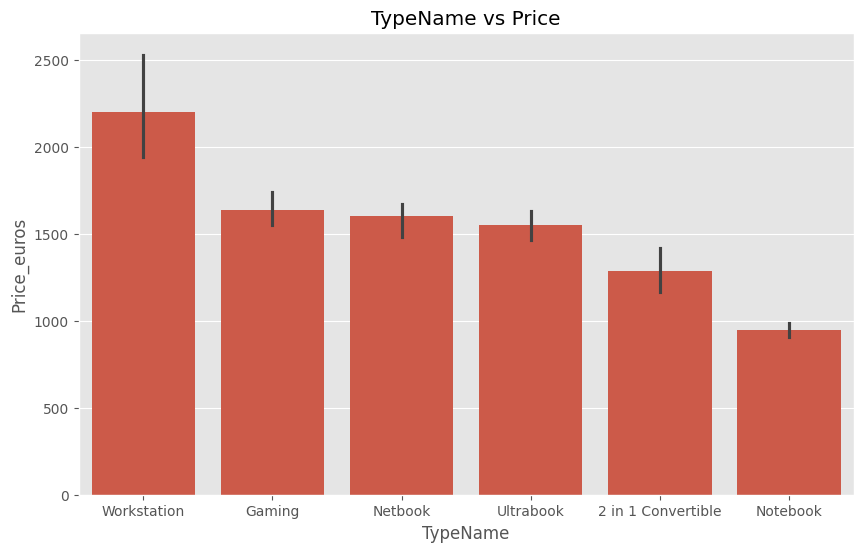

In [ ]:
# Type Name vs Price
plt.figure(figsize=(10, 6))
typename_order = df.groupby('TypeName')['Price_euros'].mean().sort_values(ascending=False).index
sns.barplot(x='TypeName', y='Price_euros', data=df, order=typename_order)
plt.title('TypeName vs Price')

<Axes: >

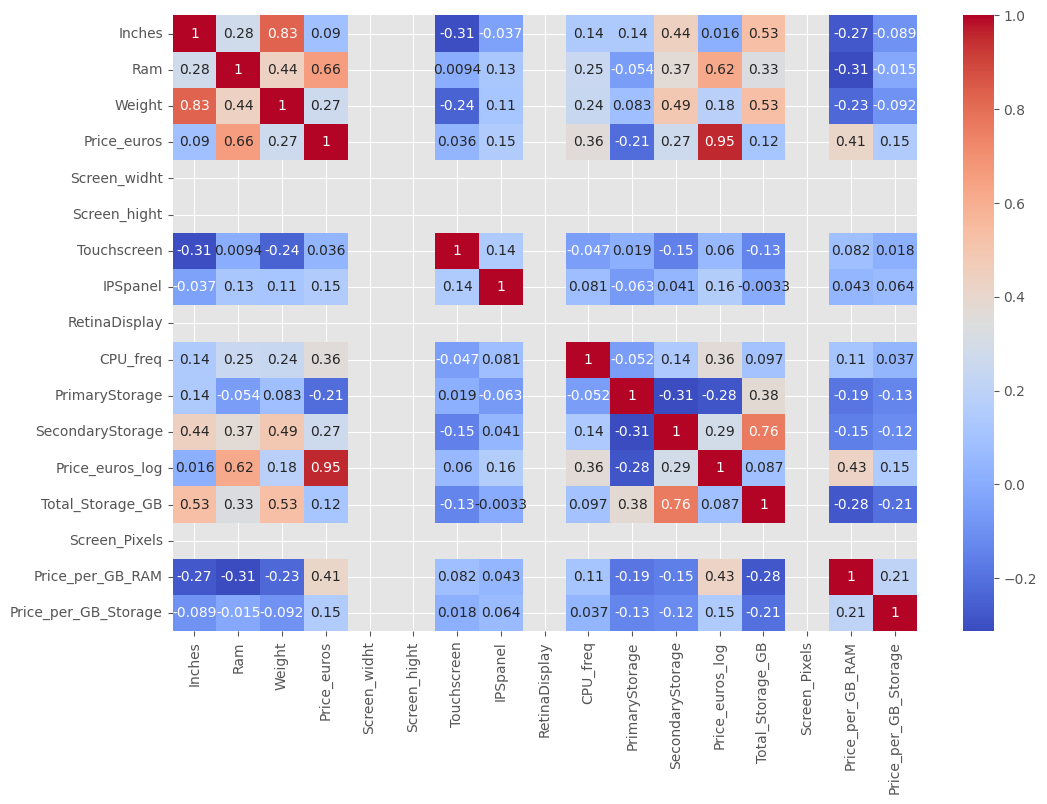

In [ ]:
plt.figure(figsize=(12, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')
#we only see strong positive relations(dark red/ red) between columns and theirself
#which is the main diagonal
#and 2 between the price and its log so basically itself
#then the relation between weight and inches which is normal and not helpfull
#also the secondary storage and total storage normal
#then the relation between Ram and price which i plotted before

In [ ]:
#some categorical Encoding again
#this converts the remaining text columns into numbers
cols_to_encode = ['Company', 'TypeName', 'OS', 'CPU_company', 'GPU_company']
df_encoded= pd.get_dummies(df, columns=cols_to_encode, drop_first=True)
#pd.get_dummies is the Pandas function that performs the transformation
#it looks at every unique value in the columns and creates the new binary (0 or 1) columns
#which made my data has more columns but more readable to models not just human
#also used drop first because if we didnt we will confuse model of the laptop is 0 at Workstation and notebook
#than there is no need for it to be 1 at gaming cause it must be a gaming laptop so thats why we are removing a category

In [ ]:
#Scaling ram and weight using MinMaxScaler to squeeze Weight and Ram into a range between 0 and 1
#This prevents the model from thinking a certain Weight has smaller impact than a certian Ram simply because of the units
#so we are telling the mode to ignore the units and just look at how much each value varies
#relative to its own minimum and maximum
scaler = MinMaxScaler()
df_encoded[['Weight', 'Ram']] = scaler.fit_transform(df_encoded[['Weight', 'Ram']])

# task 2

# import libraries

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df_encoded.dtypes
#again to know which text columns to drop

,0
Product,object
Inches,float64
Ram,float64
Weight,float64
Price_euros,float64
Screen,object
Screen_widht,int64
Screen_hight,int64
Touchscreen,int64
IPSpanel,int64


In [ ]:
#Define X and y , X are the Features so Everything in the data except the prices and non-numeric columns
# y is the Target and using the log of the price usually result in better preformance
# We drop Price ,Price log and any text columns
X = df_encoded.drop(columns=['Price_euros',
                    'Price_euros_log', 'Product', 'CPU_model',
                             'GPU_model', 'RAM_Category', 'Screen', 'PrimaryStorageType', 'SecondaryStorageType'])
y = df_encoded['Price_euros_log']

In [ ]:

#Split data 80% training, the model studies this to learn the patterns
# 20% testing to see if it actually learned or just memorized
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)
#train_test_split function takes big set of data and cut it into two separate sets
#this tells the function to put 20% of the data into the Test set so the remaining will be put into the Train set
#also computers shuffle the data before splitting it so we used 50 or any number
#so the shuffle will be the same every time we run the code
#so that results are consistent


## define and bulid the model

In [ ]:
model = LinearRegression()
#assining inputs to the model
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
#apply the test to the model to make prediction
y_pred = model.predict(X_test)
#now we have y_pred , y_test to compare

In [ ]:
#convert log values back to actual values so human can understand
actual_prices = np.exp(y_test) #calculate the exponential of all elements in the input array which is y_test,train
predicted_prices = np.exp(y_pred)

## Use RMSE, MAE, R² for regression

In [ ]:
# MAE Mean Absolute Error, its the average mistake
#it tells on average how many Euros the model is off by
#so its the easist to understand
mae= mean_absolute_error(actual_prices, predicted_prices)
print(f"Mean Absolute Error: {mae:.2f} Euros")
#saying that my model is off by ... euros

Mean Absolute Error: 183.97 Euros


In [ ]:
#Root Mean Squared Error
#how much you are failing on large outliers, so it catches huge embarrassing mistakes
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))
print(f"Root Mean Squared Error: {rmse:.2f} Euros")
#this is much higher than MAE it tells that the model is making some big mistakes on a few specific laptops

Root Mean Squared Error: 255.54 Euros


In [ ]:
#R^2 Score is a percentage,tells how much of logic behind the price the model actually captured
#by comparing the model to a dumb model that just guesses the average price of all laptops in the dataset
r2 = r2_score(y_test, y_pred) # R2 is calculated on the log values
#Since the target i gave the model was the log the R^2 is calculated based on that target
# to see how well the model did
print(f"R2 Score: {r2:.4f}")
#means that the model already understands nearly 85% of the factors that determine a laptop's price

R2 Score: 0.8471


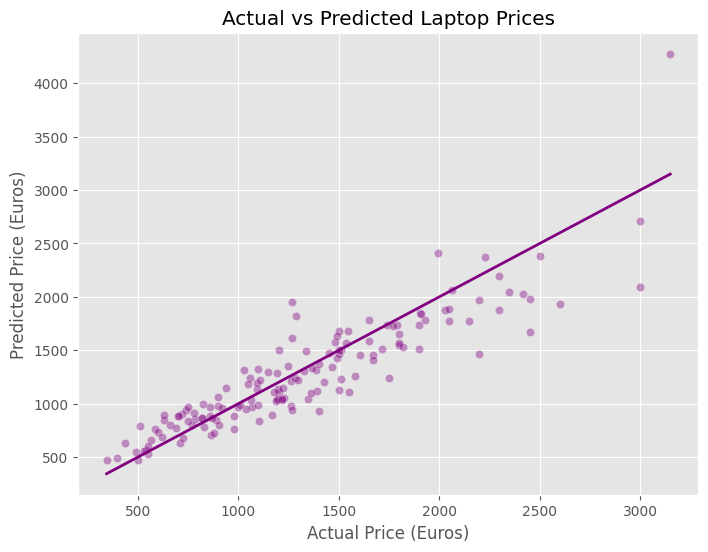

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=actual_prices, y=predicted_prices,color='purple',alpha=0.40)
#this because the X and Y coordinates are identical this creates a perfectly diagonal line
#where x=y so we can compare it with our points to know if ot predicyed the price right or not
plt.plot([actual_prices.min(), actual_prices.max()], [actual_prices.min(), actual_prices.max()], color='purple', lw=2)
plt.xlabel('Actual Price (Euros)')
plt.ylabel('Predicted Price (Euros)')
plt.title('Actual vs Predicted Laptop Prices')
plt.show()

# Apply cross-validation

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
#this proves that the Linear Regression model wasn't just lucky with the current split
#so it tests the model on 5 different sections of data to ensures our model is stable and consistent
cv_scores = cross_val_score(model, X, y, cv=5)

print(f"All 5 Cross-Validation Scores: {cv_scores}")
print(f"Average R2 Score: {cv_scores.mean():.4f}")
#well since my model is definitly unconsistent lets try advanced models

All 5 Cross-Validation Scores: [ 0.83660556  0.84569054  0.89826149 -3.98641799  0.74287667]
Average R2 Score: -0.1326


# Advanced Models

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
#same steps as the linear regression model
dt_model = DecisionTreeRegressor(random_state=50)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

actual_dt = np.exp(y_test)
predicted_dt = np.exp(y_pred_dt)

mae_dt = mean_absolute_error(actual_dt, predicted_dt)
rmse_dt= np.sqrt(mean_squared_error(actual_dt, predicted_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print(f"decision tree MAE: {mae_dt:.2f} Euros")
print(f"decision tree RMSE: {rmse_dt:.2f} Euros")
print(f"decision tree R2: {r2_dt:.4f}")
#decision tree dropped the MAE alot , increased the R2
#but didnt fix the big mistakes which is the RMSE

decision tree MAE: 46.34 Euros
decision tree RMSE: 242.97 Euros
decision tree R2: 0.9404


In [ ]:
dt_cv_scores = cross_val_score(dt_model, X, y, cv=5)

print(f"All 5 Cross-Validation Scores: {dt_cv_scores}")
print(f"Average R2 Score: {dt_cv_scores.mean():.4f}")
#shows a much more stable score than the linear regression model

All 5 Cross-Validation Scores: [0.96290181 0.91979658 0.96948813 0.90485059 0.92510047]
Average R2 Score: 0.9364


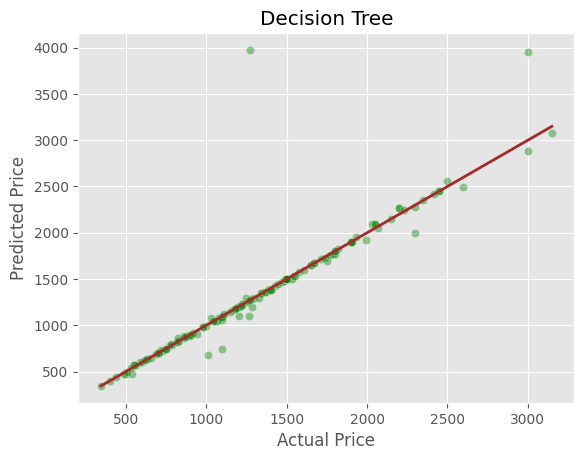

In [ ]:
sns.scatterplot(x=actual_dt, y=predicted_dt, color='green', alpha=0.4)
plt.plot([actual_prices.min(), actual_prices.max()], [actual_prices.min(), actual_prices.max()], color='brown', lw=2)
plt.title(f'Decision Tree')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()
#shows more points on the line

In [ ]:
from sklearn.ensemble import RandomForestRegressor
#lets try the next advanced model

In [ ]:
#we are telling the model to make 100 decision tree , to be more stable and consistent
rf_model = RandomForestRegressor(n_estimators=100, random_state=50)
#the same steps as the linear regression model
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

actual_rf = np.exp(y_test)
predicted_rf = np.exp(y_pred_rf)

mae_rf = mean_absolute_error(actual_rf, predicted_rf)
rmse_rf = np.sqrt(mean_squared_error(actual_rf, predicted_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"RF MAE: {mae_rf:.2f} Euros")
print(f"RF RMSE: {rmse_rf:.2f} Euros")
print(f"RF R2 Score: {r2_rf:.4f}")
#we can see that everything improved RMSE dropped and R2 increased but MAE is higher?
#bec the decision tree might be overfitting to a each specific point
#but the RMSE here is much less so RF model is better

RF MAE: 49.73 Euros
RF RMSE: 114.76 Euros
RF R2 Score: 0.9754


In [ ]:
rf_cv_scores = cross_val_score(rf_model, X, y, cv=5)

print(f"All 5 Cross-Validation Scores: {rf_cv_scores}")
print(f"Average R2 Score: {rf_cv_scores.mean():.4f}")
#shows an even more stable score

All 5 Cross-Validation Scores: [0.98058692 0.98042131 0.98395224 0.94600341 0.94247497]
Average R2 Score: 0.9667


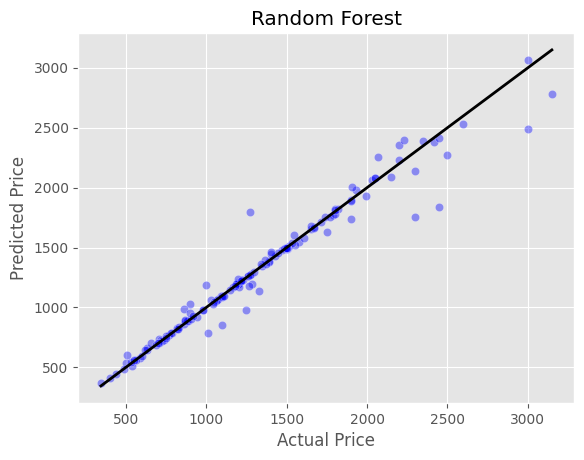

In [ ]:
sns.scatterplot(x=actual_rf, y=predicted_rf, color='blue', alpha=0.4)
plt.plot([actual_prices.min(), actual_prices.max()], [actual_prices.min(), actual_prices.max()], color='black', lw=2)
plt.title(f'Random Forest')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()
#no really far dots from the point like the dt_model plot

In [ ]:
print(f"The Random Forest error is {mae - mae_rf:.2f} Euros lower than Linear Regression")

The Random Forest error is 134.24 Euros lower than Linear Regression


In [ ]:
from xgboost import XGBRegressor
#bulids alot of trees like rf but its sequential so tree 2 tries to fix tree 1, tree 3 fixes tree 2, and so on
#it corrects it self taking small steps toward the right price making it more accurate

In [ ]:
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=50)
#learning_rate controls how much each new tree is allowed to correct the previous one
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
mae_xgb = mean_absolute_error(np.exp(y_test), np.exp(y_pred_xgb))
rmse_xgb = np.sqrt(mean_squared_error(np.exp(y_test), np.exp(y_pred_xgb)))
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"XGBoost MAE: {mae_xgb:.2f} Euros")
print(f"XGBoost RMSE : {rmse_xgb:.2f} Euros")
print(f"XGBoost R2: {r2_xgb:.4f}")
##we can see that everything improved even more
#MAE, RMSE dropped and R2 increased

XGBoost MAE: 31.35 Euros
XGBoost RMSE : 63.61 Euros
XGBoost R2: 0.9903


In [ ]:
xgb_cv_scores = cross_val_score(xgb_model, X, y, cv=5)

print(f"All 5 Cross-Validation Scores: {xgb_cv_scores}")
print(f"Average R2 Score: {xgb_cv_scores.mean():.4f}")
#making sure it gets stable scores

All 5 Cross-Validation Scores: [0.98619738 0.98356367 0.98677574 0.94093937 0.96784226]
Average R2 Score: 0.9731


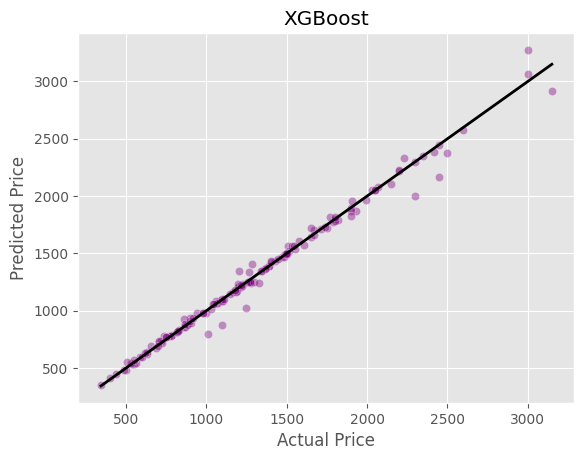

In [ ]:
sns.scatterplot(x=np.exp(y_test), y=np.exp(y_pred_xgb), color='purple', alpha=0.4)
plt.plot([actual_prices.min(), actual_prices.max()], [actual_prices.min(), actual_prices.max()], color='black', lw=2)
plt.title(f'XGBoost')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()

In [ ]:
from lightgbm import LGBMRegressor
#same as xgboost but it grows vertically, looks for the specific leaf
#that will reduce the error the most and grows it even if other branches are still short

In [ ]:
lgbm_model = LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=50)
lgbm_model.fit(X_train, y_train)
y_pred_lgbm = lgbm_model.predict(X_test)
mae_lgbm = mean_absolute_error(np.exp(y_test) , np.exp(y_pred_lgbm))
rmse_lgbm = np.sqrt(mean_squared_error(np.exp(y_test), np.exp(y_pred_lgbm)))
r2_lgbm = r2_score(y_test, y_pred_lgbm)
print(f"LightGBM MAE: {mae_lgbm:.2f} Euros")
print(f"LightGBM RMSE : {rmse_lgbm:.2f} Euros")
print(f"LightGBM R2: {r2_lgbm:.4f}")
#its accuracy is high but it can overfit on large data which what happened here

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000482 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 560
[LightGBM] [Info] Number of data points in the train set: 586, number of used features: 26
[LightGBM] [Info] Start training from score 7.036085
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [ ]:
from sklearn.neural_network import MLPRegressor

#scaling the data because Neural Networks are sensitive to the size of numbers
nn_model = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=50)
#the first hidden layer has 100 neuron, the second hidden layer has 50 neurons
#the first layer usually catches simple patterns, while the second layer catches complex relationships
#max_iter is the number of or practice rounds, neural networks learn by trial and error
#so they need to go over the data many times
nn_model.fit(X_train, y_train)

y_pred_nn = nn_model.predict(X_test)
mae_nn = mean_absolute_error(np.exp(y_test) , np.exp(y_pred_nn))
rmse_nn= np.sqrt(mean_squared_error(np.exp(y_test), np.exp(y_pred_nn)))
r2_nn= r2_score(y_test, y_pred_nn)
print(f"Neural Network MAE: {mae_nn:.2f} Euros")
print(f"Neural Network RMSE : {rmse_nn:.2f} Euros")
print(f"Neural Network R2: {r2_nn:.4f}")
#Neural Networks are data-hungry They usually need 10,000+ rows to really shine
#thats why it didnt work here

Neural Network MAE: 1317.71 Euros
Neural Network RMSE : 1436.69 Euros
Neural Network R2: -1094019.4729


In [ ]:
results_data = {
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM', 'Neural Network'],
    'MAE (Euros)': [mae, mae_dt, mae_rf, mae_xgb, mae_lgbm, mae_nn],
    'RMSE (Euros)': [rmse, rmse_dt, rmse_rf, rmse_xgb, rmse_lgbm, rmse_nn],
    'R2 Score': [r2, r2_dt, r2_rf, r2_xgb, r2_lgbm, r2_nn]
}
performance_table = pd.DataFrame(results_data)
print(performance_table)

               Model  MAE (Euros)  RMSE (Euros)      R2 Score
0  Linear Regression   183.972099    255.537521  8.470868e-01
1      Decision Tree    46.344218    242.968677  9.403612e-01
2      Random Forest    49.734253    114.757335  9.753637e-01
3            XGBoost    31.350263     63.613540  9.902955e-01
4           LightGBM    58.308278    107.579824  9.814207e-01
5     Neural Network  1317.709456   1436.693968 -1.094019e+06


# XGBoost model is the winner, its results are perfect in everyway
#so now lets do the tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
#trying to find the perfect settings so we tune the winner, instead of you manually changing numbers to see what works best
#It will try 100 and 200 tree, a cautious and a standard learning_rate, different depths or complexity for the trees
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5, 7]
}
#for every single combination of those settings, it runs a 3-fold Cross-Validation to make sure the result is consistent
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid, cv=3, scoring='r2')
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
final_model = grid_search.best_estimator_
#This saves the version of your model that got the highest R^2 score

Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}


/tmp/ipython-input-3062889713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='magma')


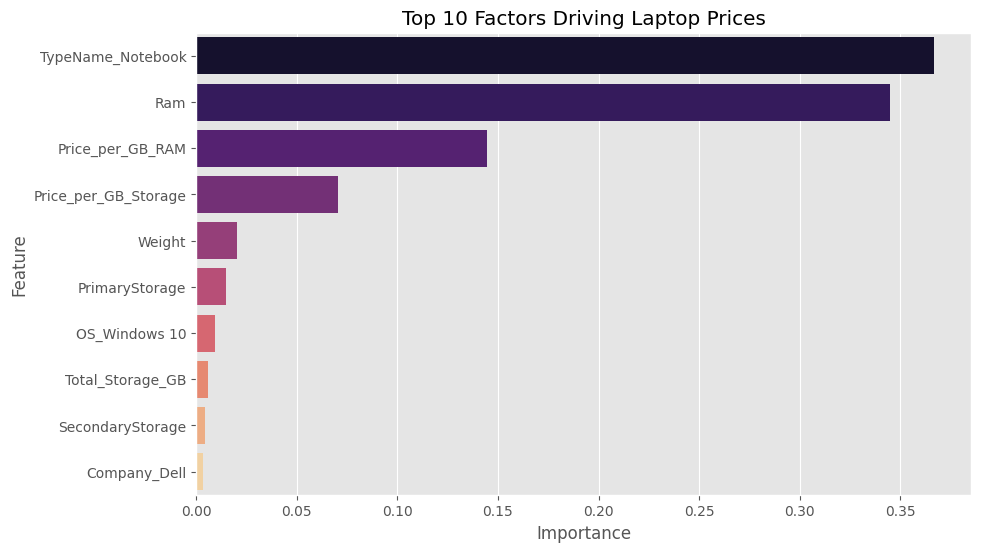

In [ ]:
#this is in the documentation part
#a plot to show what actually makes a laptop expensive
importances = final_model.feature_importances_
#XGBoost tracks how much each feature helped in reducing the error during training and put a score to each
features = X.columns
#i have already put the features in X so we use them
importance_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='magma')
plt.title('Top 10 Factors Driving Laptop Prices')
plt.show()

# i already choose a model but since i was asked in the task to use
# accuracy, precision, recall, F1-score for classification

In [ ]:
from sklearn.metrics import classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier

In [ ]:
#creating a category
#1 if price > 1200 (Expensive), 0 if lower (Budget)
y_class = (df_encoded['Price_euros'] > 1200).astype(int)
#split again but for classification
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=50)
#but we use a classifier instead of regressor
clf = RandomForestClassifier(random_state=50)
clf.fit(X_train_c, y_train_c)
y_pred_class = clf.predict(X_test_c)

# accuracy, precision, recall, F1-score
print("    classification Report expensive vs budget   ")
print(f"Accuracy: {accuracy_score(y_test_c, y_pred_class):.4f}")
print(classification_report(y_test_c, y_pred_class))

    classification Report expensive vs budget   
Accuracy: 0.9660
              precision    recall  f1-score   support

           0       0.93      1.00      0.96        68
           1       1.00      0.94      0.97        79

    accuracy                           0.97       147
   macro avg       0.97      0.97      0.97       147
weighted avg       0.97      0.97      0.97       147



# task 3

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

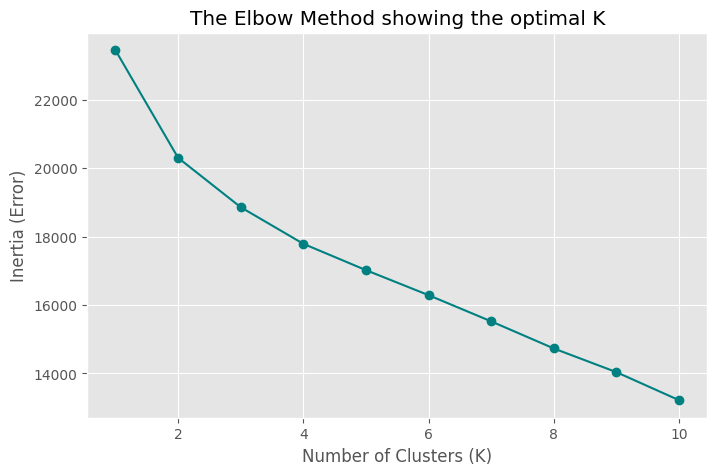

In [ ]:
#scale the data first so all features have equal importance
#bec clustering is sensitive
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#finding the optimal number of clusters with the Elbow Method
#Inertia measures how tightly packed the laptops are within their clusters
inertia = []
#if Inertia is high the groups are loose and messy, if low the groups are tight and well-defined.
K_range = range(1, 11)
#try grouping the laptops into 1 group then 2 then 3 to 10 groups
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=50, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

#Plotting the Elbow
#The Elbow Curve provides a mathematical prove for your choice
#for example if the drop from K=4 to K=5 is almost flat then K=4 is the suitable one
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o',color='teal')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Error)')
plt.title('The Elbow Method showing the optimal K')
plt.show()

In [ ]:
#applying K-Means
#using k=4, choosing 2 or 3 will leave so much error bec the drop between thwm is big
#choosing 5 or 6 would make the groups too similar to each other
kmeans = KMeans(n_clusters=4, random_state=50, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

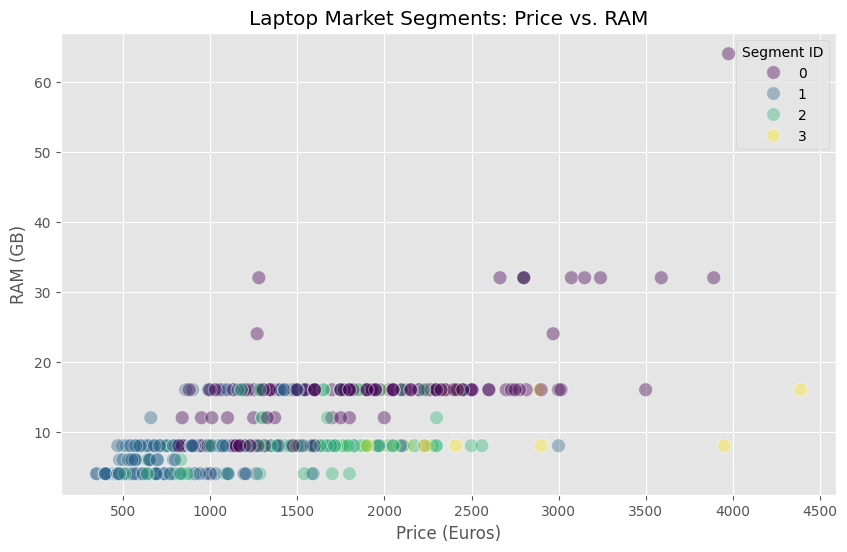

In [ ]:
#visualizing the clusters
#you will see the budget cluster in the bottom left and High-End in the top right
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Price_euros',
    y='Ram',
    hue='Cluster',
    palette='viridis',
    s=100,
    alpha=0.4
)
plt.title('Laptop Market Segments: Price vs. RAM')
plt.xlabel('Price (Euros)')
plt.ylabel('RAM (GB)')
plt.legend(title='Segment ID')
plt.show()

In [ ]:
#looking at the data to explain what is in each cluster
#Interpretation
#group by cluster and calculate averages to understand the personality of each segment
cluster_summary = df.groupby('Cluster').agg({
    'Price_euros': 'mean',
    'Ram': 'mean',
    'Total_Storage_GB': 'mean',
    'Weight': 'mean'
})
print("segment Analysis")
print(cluster_summary)
#cluster 1 is the cheapest so its for budget-conscious customers
#cluster 3 is the most expensive so its for high-value customers
#cluster 2 and 0 are a bit close in price but 0 has more qualities (higher ram and storage)

segment Analysis
         Price_euros        Ram  Total_Storage_GB    Weight
Cluster                                                    
0        1608.240340  13.475728       1148.213592  2.870830
1         930.444366   7.238938        569.073746  2.031711
2        1461.455366   9.073171        357.560976  1.455982
3        2198.267500  10.000000        407.333333  2.458750


In [ ]:
#suggesting potential business Strategies
#price numbers are based on the cluster summary we did
#only used the price in the final logic because it is the most identifiable trait
#but foe ex a laptop in the High-Value cluster doesn't just have a high price it also likely has 16GB+ RAM and an SSD
#and thats what i was asked to do
for index, row in cluster_summary.iterrows():
    print(f"\nstrategy for Cluster {index}")

    # High-Value Logic
    if row['Price_euros'] > 1500:
        print("Category: High-Value / Professional")
        print("Insight: Customers prioritize performance over price")
        print("Strategy: Recommend Loyalty Programs (VIP support, early hardware access)")

    # Budget-Conscious Logic
    elif row['Price_euros'] < 900:
        print("Category: Budget-Conscious / Students")
        print("Insight: High price sensitivity, likely looking for value")
        print("Strategy: Introduce discounts, trade-in offers, or value-for-money bundles")

    # Low-Engagement/Mid-Tier Logic
    else:
        print("Category: Mid-Tier / Standard Business")
        print("Insight: Balanced specs, potential for upselling")
        print("Strategy: Suggest targeted marketing campaigns focusing on reliability and mid-tier performance upgrades")



strategy for Cluster 0
Category: High-Value (Avg Price: 1608.24)
Insight: Customers prioritize performance over price
Strategy: Recommend Loyalty Programs (VIP support, early hardware access)

strategy for Cluster 1
Category: Mid-Tier / Standard Business
Insight: Balanced specs, potential for upselling
Strategy: Suggest targeted marketing campaigns focusing on reliability and mid-tier performance upgrades

strategy for Cluster 2
Category: Mid-Tier / Standard Business
Insight: Balanced specs, potential for upselling
Strategy: Suggest targeted marketing campaigns focusing on reliability and mid-tier performance upgrades

strategy for Cluster 3
Category: High-Value (Avg Price: 2198.27)
Insight: Customers prioritize performance over price
Strategy: Recommend Loyalty Programs (VIP support, early hardware access)


In [ ]:
print("both clusters 3 and 0 are considered to be a high-value clusters\n for customers who prioritize performance over price\n but cluster 0 has higher total storage and RAM\n just slightly more weight than cluster 3")

both clusters 3 and 0 are considered to be a high-value clusters
 for customers who prioritize performance over price
 but cluster 0 has higher total storage and RAM
 just slightly more weight than cluster 3
